In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io as sio

# Load the UMIST dataset
data = sio.loadmat("umist_cropped.mat")

# Check the dataset structure
print("Dataset keys:", data.keys())

Dataset keys: dict_keys(['__header__', '__version__', '__globals__', 'facedat', 'dirnames'])


In [2]:
# Extract the face data
faces = data["facedat"][0]

# Check the number of people
print("Number of people:", len(faces))

# Check the shape of the first person's images
print("First person's image shape:", faces[0].shape)

# Check the total number of images
total_images = sum(person.shape[2] for person in faces)
print("Total number of images:", total_images)

Number of people: 20
First person's image shape: (112, 92, 38)
Total number of images: 575


In [3]:
# Create lists to store images and labels
images = []
labels = []

# Extract images for each person
for person_id, person_faces in enumerate(faces):
    for image_index in range(person_faces.shape[2]):
        image = person_faces[:, :, image_index]

        # Convert the 2D image into a 1D array
        images.append(image.flatten())

        # Assign a label to each person
        labels.append(person_id + 1)

# Convert images into a Pandas DataFrame
df = pd.DataFrame(images)

# Add person labels
df["label"] = labels

# Display dataset information
print("DataFrame shape:", df.shape)
print("Total images:", len(df))
print("Number of unique people:", df["label"].nunique())

# Display first 5 rows
display(df.head())

DataFrame shape: (575, 10305)
Total images: 575
Number of unique people: 20


,0,1,2,3,4,5,6,7,8,9,...,10295,10296,10297,10298,10299,10300,10301,10302,10303,label
0,233,234,234,233,234,232,232,168,99,78,...,154,151,147,143,140,141,141,140,136,1
1,234,234,234,234,233,232,202,98,79,77,...,154,150,147,141,140,137,138,137,137,1
2,234,234,234,234,233,230,225,109,85,84,...,174,168,164,157,152,151,148,145,145,1
3,234,234,234,234,234,234,234,232,229,205,...,168,162,157,155,150,144,144,142,143,1
4,234,234,234,234,234,234,234,234,229,211,...,176,170,164,162,157,152,150,148,148,1


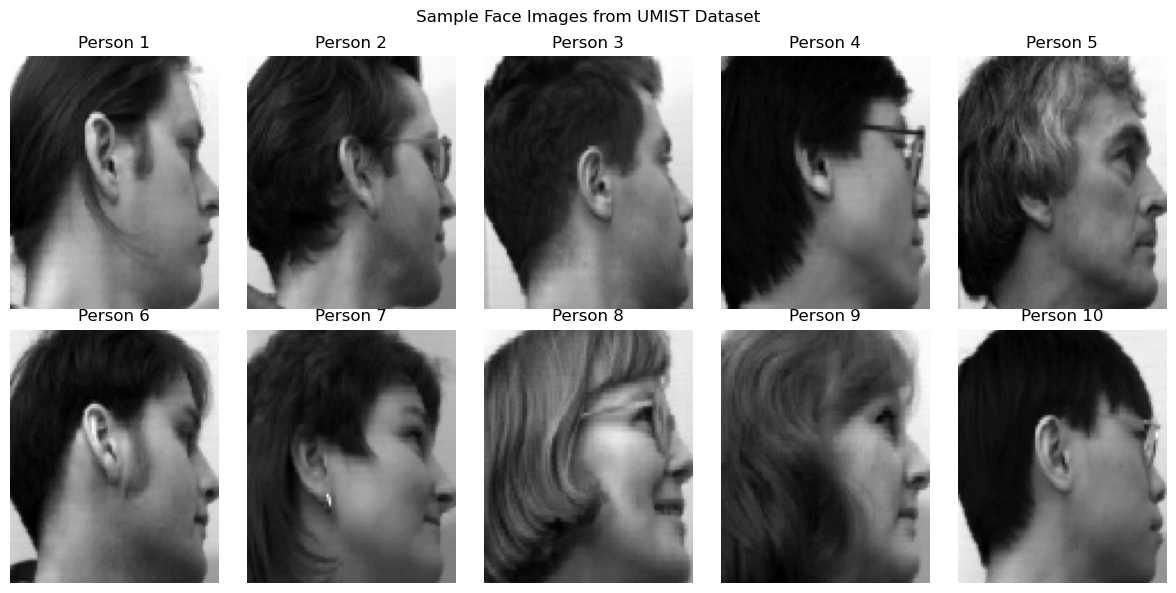

In [4]:
# Display sample face images from the UMIST dataset
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    # Select the first image of each person
    image = faces[i][:, :, 0]

    # Display the face image
    ax.imshow(image, cmap="gray")

    # Add the person's label
    ax.set_title(f"Person {i + 1}")
    ax.axis("off")

plt.suptitle("Sample Face Images from UMIST Dataset")
plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

# Separate image pixels and person labels
X = df.drop(columns=["label"])
y = df["label"]

# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

# Display dataset sizes
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

print("\nTraining percentage:", round(len(X_train) / len(df) * 100, 2))
print("Validation percentage:", round(len(X_val) / len(df) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(df) * 100, 2))

Training images: 402
Validation images: 86
Testing images: 87

Training percentage: 69.91
Validation percentage: 14.96
Testing percentage: 15.13


In [6]:
from sklearn.preprocessing import MinMaxScaler

# Create a MinMaxScaler
scaler = MinMaxScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler for validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Check the scaled data
print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nTraining minimum:", X_train_scaled.min())
print("Training maximum:", X_train_scaled.max())

Training shape: (402, 10304)
Validation shape: (86, 10304)
Testing shape: (87, 10304)

Training minimum: 0.0
Training maximum: 1.0000000000000002


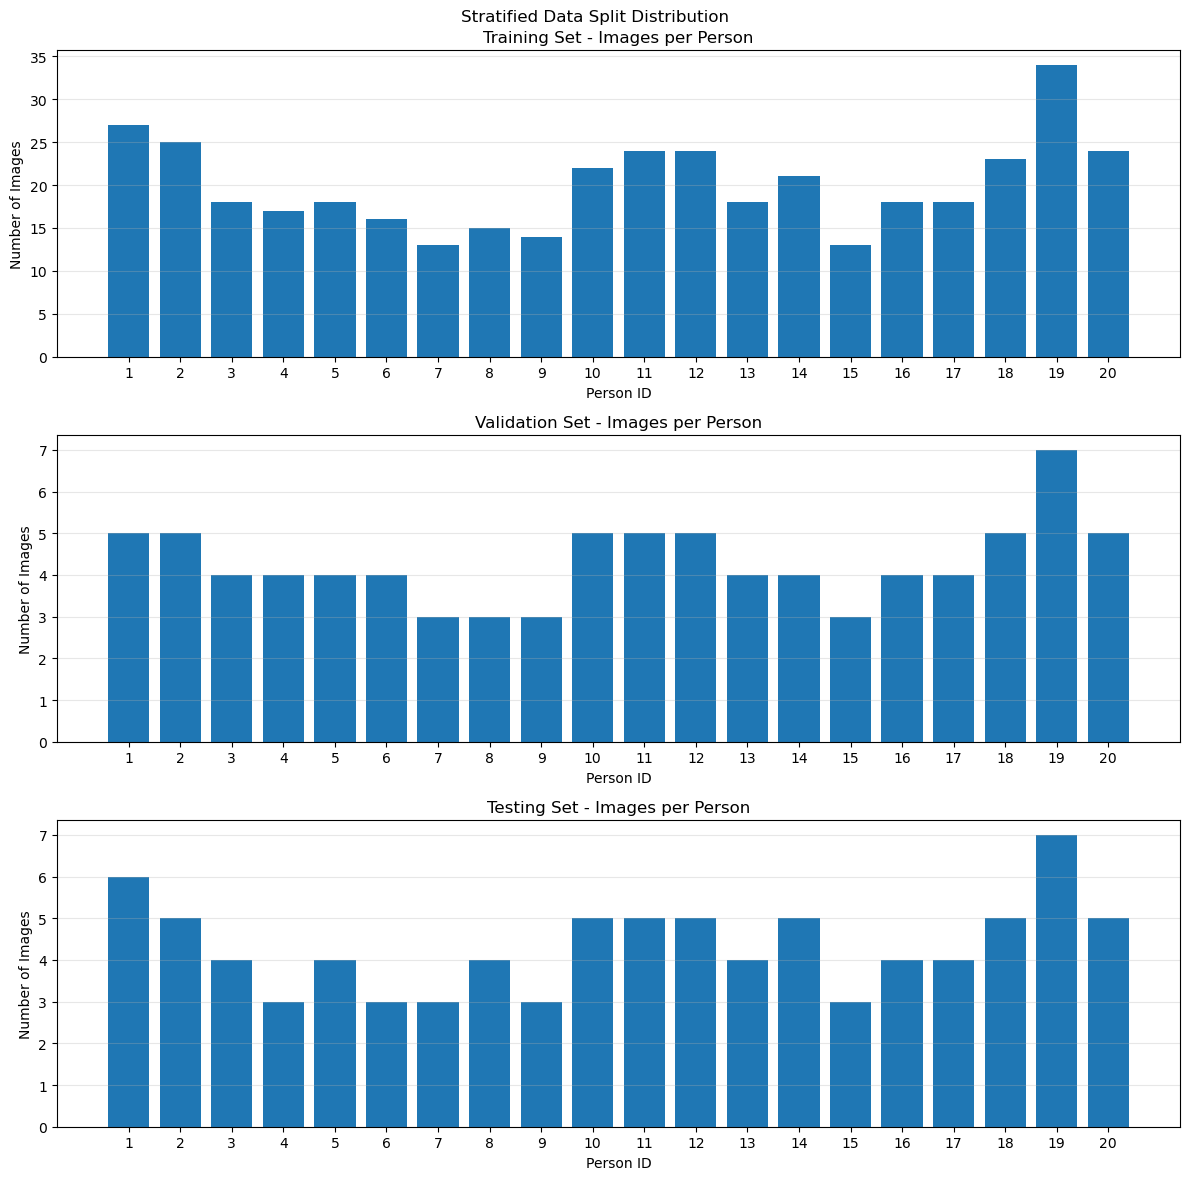

In [7]:
# Count images for each person in each dataset
train_counts = y_train.value_counts().sort_index()
val_counts = y_val.value_counts().sort_index()
test_counts = y_test.value_counts().sort_index()

# Create three distribution graphs
fig, axes = plt.subplots(3, 1, figsize=(12, 12))

datasets = [
    ("Training Set", train_counts),
    ("Validation Set", val_counts),
    ("Testing Set", test_counts)
]

for ax, (title, counts) in zip(axes, datasets):
    ax.bar(counts.index, counts.values)
    ax.set_title(f"{title} - Images per Person")
    ax.set_xlabel("Person ID")
    ax.set_ylabel("Number of Images")
    ax.set_xticks(range(1, 21))
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Stratified Data Split Distribution")
plt.tight_layout()

# Save the figure for the project report
plt.savefig("data_split_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [8]:
from sklearn.decomposition import PCA

# Test different numbers of PCA components
component_options = [10, 20, 50, 100]
explained_variances = []

for n in component_options:
    # Create PCA model
    pca = PCA(n_components=n, svd_solver="randomized",
              random_state=42)

    # Fit PCA only on training data
    pca.fit(X_train_scaled)

    # Calculate total explained variance
    total_variance = pca.explained_variance_ratio_.sum()
    explained_variances.append(total_variance)

    print(f"{n} components: {total_variance * 100:.2f}% explained variance")

10 components: 67.04% explained variance
20 components: 78.91% explained variance
50 components: 89.75% explained variance
100 components: 95.08% explained variance


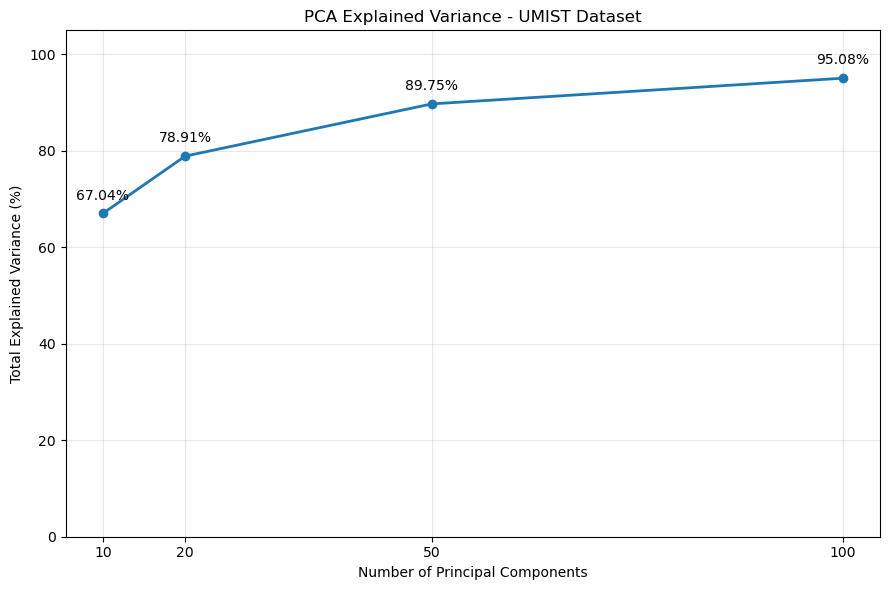

In [9]:
# Plot PCA explained variance
plt.figure(figsize=(9, 6))

plt.plot(
    component_options,
    np.array(explained_variances) * 100,
    marker="o",
    linewidth=2
)

# Add percentage labels
for n, variance in zip(component_options, explained_variances):
    plt.annotate(
        f"{variance * 100:.2f}%",
        (n, variance * 100),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.title("PCA Explained Variance - UMIST Dataset")
plt.xlabel("Number of Principal Components")
plt.ylabel("Total Explained Variance (%)")
plt.xticks(component_options)
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save graph for final report
plt.savefig("pca_explained_variance.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [10]:
from sklearn.decomposition import PCA

# Select 100 PCA components
pca_final = PCA(
    n_components=100,
    svd_solver="randomized",
    random_state=42
)

# Fit PCA only on the training data
X_train_pca = pca_final.fit_transform(X_train_scaled)

# Transform validation and testing data
# using the same fitted PCA model
X_val_pca = pca_final.transform(X_val_scaled)
X_test_pca = pca_final.transform(X_test_scaled)

# Display the new dataset shapes
print("Training PCA shape:", X_train_pca.shape)
print("Validation PCA shape:", X_val_pca.shape)
print("Testing PCA shape:", X_test_pca.shape)

# Check total explained variance
print(
    "\nTotal explained variance:",
    round(
        pca_final.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

Training PCA shape: (402, 100)
Validation PCA shape: (86, 100)
Testing PCA shape: (87, 100)

Total explained variance: 95.08 %


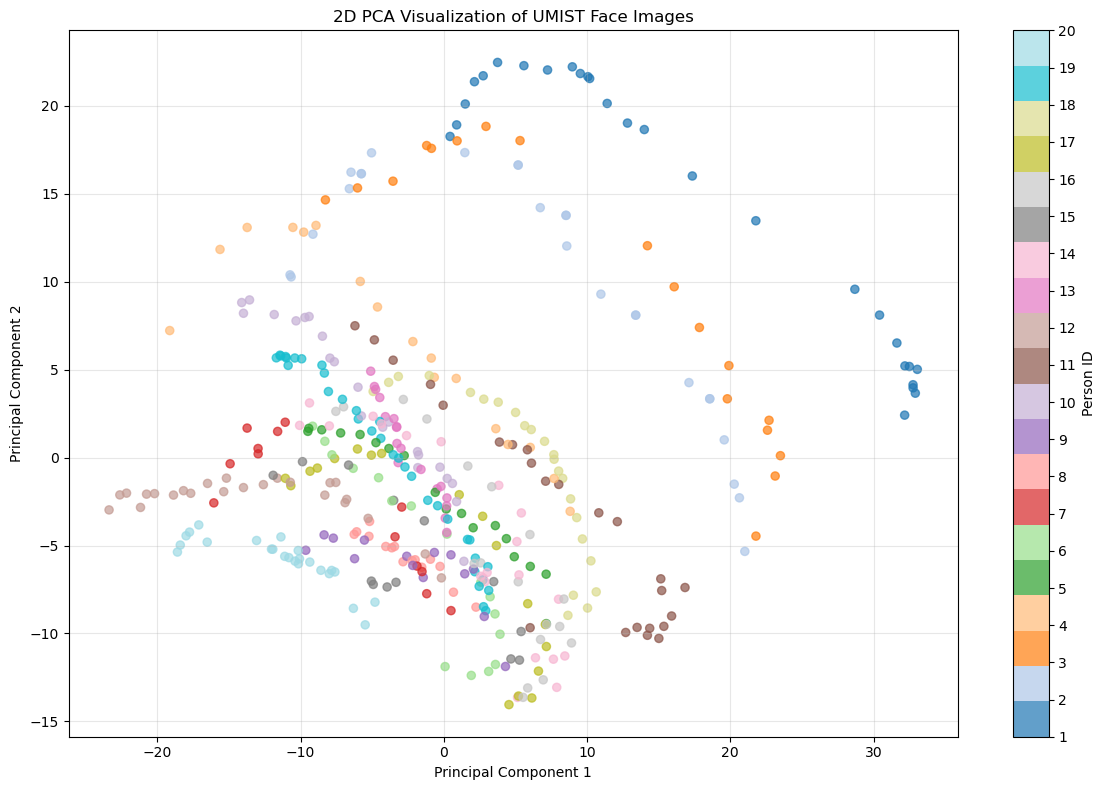

In [11]:
# Create a 2D PCA visualization using training data
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train.to_numpy(),
    cmap="tab20",
    s=35,
    alpha=0.7
)

# Add labels and title
plt.title("2D PCA Visualization of UMIST Face Images")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

# Add colorbar showing person labels
cbar = plt.colorbar(scatter, ticks=range(1, 21))
cbar.set_label("Person ID")

plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the figure for the final report
plt.savefig(
    "pca_2d_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
import numpy as np
import joblib

# Save normalized datasets and labels
np.savez_compressed(
    "umist_preprocessed_data.npz",
    X_train=X_train_scaled,
    X_val=X_val_scaled,
    X_test=X_test_scaled,
    y_train=y_train.to_numpy(),
    y_val=y_val.to_numpy(),
    y_test=y_test.to_numpy()
)

# Save PCA-reduced datasets and labels
np.savez_compressed(
    "umist_pca_data.npz",
    X_train_pca=X_train_pca,
    X_val_pca=X_val_pca,
    X_test_pca=X_test_pca,
    y_train=y_train.to_numpy(),
    y_val=y_val.to_numpy(),
    y_test=y_test.to_numpy()
)

# Save fitted scaler and PCA model
joblib.dump(scaler, "umist_scaler.pkl")
joblib.dump(pca_final, "umist_pca_model.pkl")

print("All datasets and models saved successfully!")

All datasets and models saved successfully!
